# Binary Digit Classifier

### Daniel Graham - 620171166

We have been offered a job at ML Solutions Limited to create a neural network classifier that can classify images of written binary digits (1 or 0).

In [31]:
import tensorflow as tf
import numpy as np

In [32]:
from tensorflow.keras.datasets import mnist

In [33]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [34]:
x_train.shape, x_test.shape

((60000, 28, 28), (10000, 28, 28))

Now we want to take out the 1's and 0's from this dataset so that we can do classification on those. Here we are extracting the input data and their respective labels for those whose labeles have either 0 or 1.

In [35]:
x_train, y_train = x_train[(y_train==1) | (y_train==0)],y_train[(y_train==1) | (y_train==0)]

In [36]:
x_train.shape, y_train.shape

((12665, 28, 28), (12665,))

We do the same on the test data

In [37]:
x_test, y_test = x_test[(y_test==1) | (y_test==0)], y_test[(y_test==1) | (y_test==0)]

In [38]:
x_test.shape, y_test.shape

((2115, 28, 28), (2115,))

Let us see what our data looks like. We will pick a random instance from the dataset and visualize it.

Label:  1


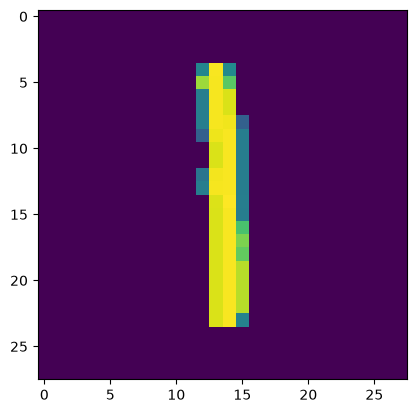

In [39]:
import random
import matplotlib.pyplot as plt
picked_idx = random.randint(0, x_train.shape[0]-1)

img_picked = x_train[picked_idx]
label = y_train[picked_idx]

plt.imshow(img_picked)
print('Label: ', label)


# Preprocessing

Before we are ready to train our predict whether an image is a 1 or a 0, we need to do some preprocessing on the data.

In [40]:
# Neural networks play better with small numbers. Images tend to have pixel values between 0 and 255.
# Rescale this to 0-1. Hint try dividing
# Do this to x_train and x_test
# Remember to store the output back into x_train and x_test

x_train = x_train / 255.0
x_test = x_test / 255.0

In [41]:
# Since you will be using a regular Dense neural network. The network expects your data to be flattened from 2D to 1D
# Rehsape the data from (N, 28, 28) to (N, 784) N represents number of images.
# Each image is 28x28, we want to chage that to one flat row with 784

x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

In [42]:
x_train.shape,x_test.shape

((12665, 784), (2115, 784))

# Create Model

Create a neural network model using tensorflow with at least 1 hidden layer. The output layer must have 1 unit. Experiment with different number of layers and number of units in each layer. This is where your creativitiy as a machine learning engineer comes in to play.

In [43]:
# Ensure the output layer uses sigmoid for activation
# Finish the line below
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,353 (204.50 KB)

 Trainable params: 52,353 (204.50 KB)

 Non-trainable params: 0 (0.00 B)

Compile the model

In [44]:
# Ensure you use the binary cross entropy loss function and sgd for your optmizer
model.compile(loss='binary_crossentropy', optimizer='sgd', metrics=['accuracy'])

Now to train the model. Store the ouput of model.fit in a vairable called history as we are going to use this to plot the train accuracy and loss. Try different values for batch size and epochs. The aim is to get the highest test accuaracy possible.

In [45]:
# Uncomment and finish the line below
history = model.fit(x_train, y_train, epochs=10, batch_size=32)

Epoch 1/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9931 - loss: 0.1109
Epoch 2/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9977 - loss: 0.0151
Epoch 3/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9981 - loss: 0.0100
Epoch 4/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9983 - loss: 0.0080
Epoch 5/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9984 - loss: 0.0068
Epoch 6/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9983 - loss: 0.0060
Epoch 7/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9984 - loss: 0.0055
Epoch 8/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9987 - loss: 0.0050
Epoch 9/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9988 - loss: 0.0047
Epoch 10/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9989 - loss: 0.0044


# Evalualtion

Let's look at the plot of loss and accuracy. You should see accuracy going up and loss going down.

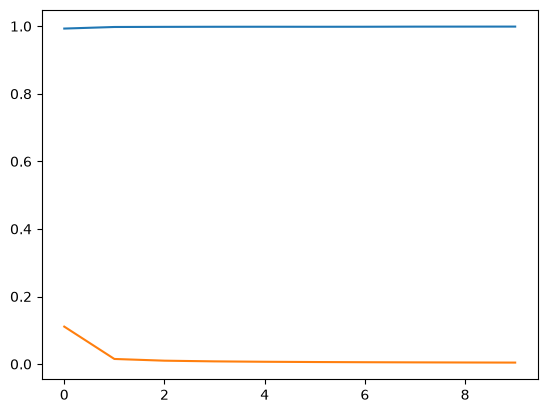

In [46]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['loss'])

Let us evaluate our model. Remember in machine learning what we are most interested in is the accuracy on the test dataset as this data represents data that the model has not seen during training so it should test the model's ability to generalize to new data.

In [47]:
# Call the evaluate function on x_test and y_test, store output in variable called out
# Finish line below
out = model.evaluate(x_test, y_test)
print('Accuracy {:.2f}%'.format(out[1]*100))

67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9991 - loss: 0.0024
Accuracy 99.91%


(784,)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
Label:  1
Predicited Label 1


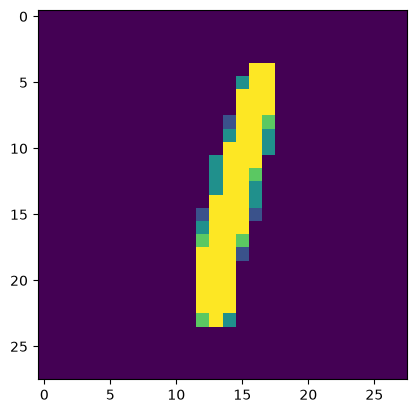

In [48]:
picked_idx = random.randint(0, x_test.shape[0]-1)

img_picked = x_test[picked_idx]
label = y_test[picked_idx]
print(img_picked.shape)
pred_label = model.predict(img_picked.reshape(1, -1))

plt.imshow(img_picked.reshape(28, 28))
print('Label: ', label)
print('Predicited Label', 1 if pred_label > 0.5 else 0)

# Logistic Regression Using SGD

$$\sigma (x) = \frac {1}{1 + e^{-x}}$$
$$y_{pred} = \sigma (W \cdot X^{T} + b)$$

In [49]:
# N - batch size
# W - weight of shape (1, num_features)
# b - bias of shape (1,)
# X - matrix of shape (N, num_features)
# returns output of  ypred of shape (N,) **make sure to reshape**
# note you have to find the dot product of W and the transpose of X (look up how to do this using numpy)
def model_predict(W, b, X):

  def activation_fn(y):
    # return  sigmoid function applied to y
    # note there is a function called np.exp
    y = np.clip(y, -500, 500)
    return 1 / (1 + np.exp(-y))
  
  y = np.dot(W, X.T) + b      # shape (1, N)
  y = y.reshape(-1)           # shape (N,)
  return activation_fn(y)


$$L = -\frac{1}{N}\sum y_{target}log(y_{pred}) + (1-y_{target})log(1-y_{pred})$$

In [50]:
# y_target - vector of targets of shape (N,)
# y_pred - vector of predictions of shape (N, )
# returns output of binary cross entropy loss function above
# **note you can find the mean using np.mean**
def loss_fn(y_target, y_pred):
    eps = 1e-12  # avoids log(0)
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_target * np.log(y_pred) + (1 - y_target) * np.log(1 - y_pred))

$$\frac{\partial{L}}{\partial{W}} = \frac{1}{N}(y_{pred}-y_{target})\cdot X$$
$$\frac{\partial{L}}{\partial{b}} = \frac{1}{N}\sum (y_{pred}-y_{target})$$

In [51]:
# N - batch size
# y_pred - vector of predicitions of shape (N,)
# y_target - vector of targets of shape (N,)
# X - matrix of shape (N, num_features)
# returns dl_dw, dl_db - parital derivative of loss with respect to the weights, partial derivative of loss with respect
# to bias note you have to find the dot product
def gradient_calc(y_pred, y_target, X):
  N = len(X)
  error = y_pred - y_target                    # shape (N,)
  dl_dw = (np.dot(error, X) / N).reshape(1, -1)  # shape (1, num_features)
  dl_db = np.array([np.sum(error) / N])          # shape (1,)
  
  return dl_dw, dl_db

# Gradient descent
$$ W = W - \alpha \frac{\partial L}{\partial W}$$
$$ b = b - \alpha \frac{\partial L}{\partial b}$$

In [52]:
# W - weight of shape (1, num_features)
# b - bias of shape(1,)
# alpha - learning rate
# dl_dw - partial derivative of loss with respect to weight of shape (1, num_features)
# dl_db - partial derivative of loss with respect to bias (1,)
# returns W, b - updated weight and bias
def gradient_step(W, b, dl_dw, dl_db, alpha=0.01):
  W = W - alpha * dl_dw
  b = b - alpha * dl_db
  return W, b

Initialize weight and bias

In [53]:
W = np.random.randn(1, 784)
b = np.zeros(1,)

In [54]:
num_epochs = 20 #iterations through the entire dataset
batch_size = 16
alpha = 0.001 # learning rate

In [55]:
losses = []
for i in range(num_epochs):
  num_batches = len(x_train)//batch_size # split into mini batches
  for j in range(num_batches):
    X = x_train[j*batch_size:(j+1)*batch_size]
    y_target = y_train[j*batch_size:(j+1)*batch_size]
    y_pred = model_predict(W, b, X)
    loss = loss_fn(y_target, y_pred)
    dl_dw, dl_db = gradient_calc(y_pred, y_target, X)
    W, b = gradient_step(W, b, dl_dw, dl_db, alpha)
  losses.append(loss)
  print('Epoch: ', i, ' Loss: ', loss)

Epoch:  0  Loss:  2.0734977969342547
Epoch:  1  Loss:  1.1596234603637765
Epoch:  2  Loss:  0.7587265477269927
Epoch:  3  Loss:  0.5741822823400348
Epoch:  4  Loss:  0.4687106741221194
Epoch:  5  Loss:  0.39951411630493255
Epoch:  6  Loss:  0.3505467118111787
Epoch:  7  Loss:  0.313724355452562
Epoch:  8  Loss:  0.2845269178011613
Epoch:  9  Loss:  0.2603887393229603
Epoch:  10  Loss:  0.2398177557972914
Epoch:  11  Loss:  0.22190214092438293
Epoch:  12  Loss:  0.20605032694500494
Epoch:  13  Loss:  0.19185699039517826
Epoch:  14  Loss:  0.17903200371473077
Epoch:  15  Loss:  0.16736039528780747
Epoch:  16  Loss:  0.15667824567540486
Epoch:  17  Loss:  0.14685742243011832
Epoch:  18  Loss:  0.1377955791905076
Epoch:  19  Loss:  0.12940942825001298


Let us now plot the loss

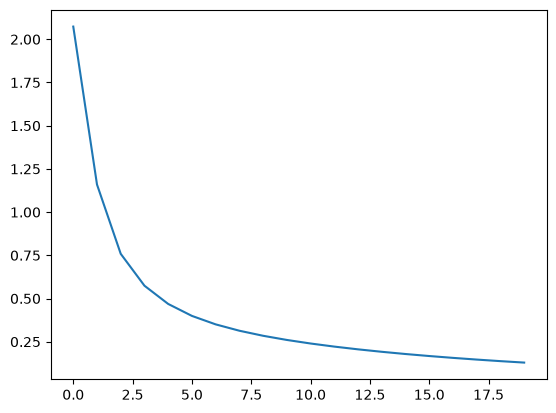

In [56]:
plt.plot(losses)

# Evaluation/Test

(784,)
Label:  1
Predicited Label 1


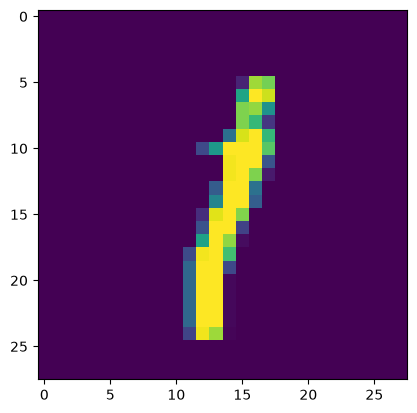

In [57]:
picked_idx = random.randint(0, x_test.shape[0]-1)

img_picked = x_test[picked_idx]
label = y_test[picked_idx]
print(img_picked.shape)
pred_label = model_predict(W, b, img_picked.reshape(1, -1))
plt.imshow(img_picked.reshape(28, 28))
print('Label: ', label)
print('Predicited Label', 1 if pred_label > 0.5 else 0)

Let us see how well your model did.

In [58]:
eval_pred = model_predict(W, b, x_test)
eval_pred = (eval_pred > 0.5).astype(float) # anything with more than 50% probability is seen as a 1
accuracy = np.mean((eval_pred == y_test).astype(float))
print('Accuracy: {:.2f}%'.format(float(accuracy*100)))

Accuracy: 98.30%


# Convolutional Neural Network

See if you can create a convolutional neural network to get even better accuracy.

In [59]:
x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

cnn.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
cnn_history = cnn.fit(x_train_cnn, y_train, epochs=5, batch_size=32, validation_split=0.1)

cnn_out = cnn.evaluate(x_test_cnn, y_test)
print('CNN Accuracy {:.2f}%'.format(cnn_out[1]*100))

Epoch 1/5
357/357 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.9944 - loss: 0.0260 - val_accuracy: 0.9992 - val_loss: 9.9605e-04
Epoch 2/5
357/357 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9989 - loss: 0.0034 - val_accuracy: 0.9992 - val_loss: 8.4391e-04
Epoch 3/5
357/357 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9994 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 5.8150e-04
Epoch 4/5
357/357 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9994 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 1.0334e-04
Epoch 5/5
357/357 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9996 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 1.3749e-04
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9995 - loss: 0.0014  
CNN Accuracy 99.95%
